# Dúvidas a se confirmar

0. PubChem AID 1626 como exemplo, ok?
É uma triagem de HTS pública de verdade (inibição de *M. tuberculosis* H37Rv), 2.044 ativos em 211.608 compostos testados, 0,97% de acerto. É o mesmo tipo de dado público de HTS dos modelos bayesianos da referência 24 do artigo, e a taxa abaixo de 1% é a que o artigo cita como padrão do HTS. Ao contrário dos outros notebooks, aqui não serve o ChEMBL de COX-2: o Repository pede explicitamente um conjunto de HTS, e um conjunto com 59% de ativas esconderia o papel da probabilidade a priori.

1. Subamostra dos inativos ou a triagem completa?
Hoje o notebook fica com os 2.044 ativos e sorteia 20.440 inativos (semente fixa), o que dá ~22 mil moléculas e poucos minutos de download. Com `INACTIVES_PER_ACTIVE = None` ele baixa os 211.608, o que leva perto de meia hora e gera um arquivo de uns 15 MB. A proporção de ativos da amostra (9%) não é a da triagem, e por isso a priori verdadeira (0,97%) é informada ao modelo explicitamente.

2. "RDKit fragment counts" = os 85 contadores de `rdkit.Chem.Fragments`, ok?
É a leitura literal do Repository: cada descritor conta quantas vezes um grupo funcional aparece na molécula. As alternativas seriam contagens de subestruturas Morgan ou chaves MACCS, que já não são "fragment counts" no sentido do módulo.

3. `MultinomialNB` sobre as contagens, com `BernoulliNB` sobre presença/ausência como comparação, ok?
A formulação multinomial é a feita para contagens. A comparação curta mostra o que se perde ao jogar fora a quantidade e manter só "tem ou não tem".

4. Informar a priori real da triagem (0,97%) ou deixar o modelo estimá-la da amostra?
Com a priori real as probabilidades ficam na escala do mundo real; com a estimada elas ficam dez vezes maiores que a chance verdadeira. O ranking é o mesmo nos dois casos.

5. Métricas: ROC-AUC, fator de enriquecimento e taxa de acerto no topo, mais MCC, ok?
Com 1% de ativos a acurácia não informa nada: um modelo que chama tudo de inativo acerta 99%. Por isso o notebook avalia o ranking, que é o uso que a Tabela 8 indica para o método (B2, priorizar/triar).

6. Divisão 80/20 ao acaso ou por scaffold?
Por scaffold a estimativa fica mais estrita. Valeria mudar nos quatro notebooks juntos, para os números continuarem comparáveis.

# Naive Bayes Screening Classifier on Fragment Counts

## Objective and overview

This notebook builds a naive Bayes classifier that scores molecules for activity
using RDKit fragment counts as features, and benchmarks it on a public
high-throughput screening (HTS) dataset.

A naive Bayes classifier estimates the probability that a compound is active
given its descriptor profile by combining two separate pieces of evidence: the
prior probability of activity in the library being screened, and the likelihood
of the observed features under each class. "Naive" refers to the assumption that
features are conditionally independent of each other, which keeps training to a
single pass of counting and makes the model scale linearly with the number of
compounds.

Because real screening libraries contain far more inactives than actives, the
useful output is not a hard active/inactive label but a score that ranks a
library, so the notebook evaluates how many known actives are recovered in the
top fraction of the ranking. Fragment counts also make the fitted model
readable: the per-feature likelihood ratios say which chemical groups the data
associates with activity.

## Inputs and setup

The training data must be a CSV file with:

- `smiles`: the molecular structure as a SMILES string.
- `activity`: the assay outcome (`active` or `inactive`).

Labels are expected to come from a single assay with one activity criterion, as
in an HTS campaign. The prior probability of activity should reflect the library
actually screened, which may differ from the proportion of classes in the file
if inactives were subsampled.

Dependencies: RDKit, scikit-learn, pandas, NumPy and Matplotlib. The worked
example downloads its data from PubChem using the standard library only.

In [1]:
from datetime import date
from pathlib import Path
import random
import time
import urllib.parse
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem import Fragments
from sklearn.metrics import matthews_corrcoef, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import BernoulliNB, MultinomialNB

RDLogger.DisableLog("rdApp.*")

Configuration in one place. Values marked *provisional* are choices made for
this notebook rather than requirements of the method, and are the ones to revisit
for a different dataset.

In [2]:
DATA_FILE = "data/pubchem_aid1626_mtb.csv"
SMILES_COLUMN = "smiles"
LABEL_COLUMN = "activity"
ACTIVE_LABEL = "active"

ACTIVE_PRIOR = None          # None estimates the prior from the data; the example below sets it explicitly
COUNT_SMOOTHING = 1.0        # provisional: pseudo-count added to every fragment (Laplace)
TEST_SIZE = 0.2              # provisional
CV_FOLDS = 5                 # provisional
TOP_FRACTIONS = (0.005, 0.01, 0.02, 0.05, 0.10, 0.20)   # provisional: fractions of the ranking to report
MIN_FRAGMENT_SUPPORT = 100   # provisional: molecules a fragment must occur in to enter the readability table
RANDOM_SEED = 0

## Data preparation (worked example)

The example uses PubChem BioAssay **AID 1626**, a public primary HTS for
inhibitors of *Mycobacterium tuberculosis* H37Rv: 2,044 compounds flagged active
and 209,564 flagged inactive, a 0.97% hit rate. It was chosen because the
Repository asks for a public HTS dataset, because it is the same kind of public
Mtb screening data used by the dual-event Bayesian models in reference 2, and
because its sub-1% hit rate is the regime this method is meant for.

The assay's own criterion defines a compound as active when it inhibited growth by
more than 30% at some concentration of the dose-response follow-up, and inactive
when inhibition stayed below 30% at every dose (or below 80% in the primary
screen). Compounds the depositor marked inconclusive are not downloaded.

Downloading every inactive compound takes about half an hour and produces a file
of roughly 15 MB, so by default the notebook keeps all actives and a fixed random
sample of ten inactives per active (~22,000 molecules, a few minutes). Setting
`INACTIVES_PER_ACTIVE = None` retrieves the whole screen. Subsampling changes the
proportion of actives in the file but not the prior used by the model, which is
taken from the full assay counts below.

In [3]:
PUBCHEM_BASE = "https://pubchem.ncbi.nlm.nih.gov/rest/pug"
PUBCHEM_AID = 1626
INACTIVES_PER_ACTIVE = 10      # provisional; None keeps every inactive compound
DOWNLOAD_DATE = date(2026, 11, 6)

# Outcome counts of the full assay, from the PubChem assay record. They define the
# prior probability of activity in the screened library, independently of how many
# inactives are kept in the local file.
ASSAY_ACTIVE_COUNT = 2044
ASSAY_INACTIVE_COUNT = 209564
ACTIVE_PRIOR = ASSAY_ACTIVE_COUNT / (ASSAY_ACTIVE_COUNT + ASSAY_INACTIVE_COUNT)
print(f"AID {PUBCHEM_AID}, outcomes retrieved on {DOWNLOAD_DATE}: "
      f"screening prior = {ACTIVE_PRIOR:.5f} ({100 * ACTIVE_PRIOR:.2f}% of the library)")

AID 1626, outcomes retrieved on 2026-11-06: screening prior = 0.00966 (0.97% of the library)


In [4]:
def _pubchem_post(url, payload, retries=4):
    body = urllib.parse.urlencode(payload).encode()
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, body, timeout=120) as response:
                return response.read().decode()
        except Exception as error:
            if attempt == retries - 1:
                raise RuntimeError(f"PubChem request to {url} failed: {error}") from error
            time.sleep(2 ** attempt)


def fetch_assay_cids(aid, outcome):
    "Compound identifiers with a given outcome ('active' or 'inactive') in a PubChem assay."
    url = f"{PUBCHEM_BASE}/assay/aid/{aid}/cids/TXT?cids_type={outcome}"
    with urllib.request.urlopen(url, timeout=300) as response:
        text = response.read().decode()
    return [int(line) for line in text.split() if line.strip()]


def fetch_smiles(cids, chunk_size=400):
    "SMILES for a list of PubChem compound identifiers, requested in chunks."
    url = f"{PUBCHEM_BASE}/compound/cid/property/SMILES/CSV"
    smiles = {}
    for start in range(0, len(cids), chunk_size):
        chunk = cids[start:start + chunk_size]
        for line in _pubchem_post(url, {"cid": ",".join(map(str, chunk))}).splitlines()[1:]:
            cid, _, value = line.partition(",")
            value = value.strip().strip('"')
            if value:
                smiles[int(cid)] = value
        time.sleep(0.2)
    return smiles


def build_screening_dataset(aid, path, inactives_per_active=None, seed=RANDOM_SEED):
    "Download one PubChem assay as a CSV of smiles/activity, optionally subsampling inactives."
    actives = fetch_assay_cids(aid, "active")
    inactives = fetch_assay_cids(aid, "inactive")
    if not actives:
        raise ValueError(f"Assay {aid} reports no active compounds; it cannot be used for training.")
    print(f"AID {aid}: {len(actives)} active, {len(inactives)} inactive")

    kept = inactives
    if inactives_per_active is not None:
        wanted = min(len(inactives), inactives_per_active * len(actives))
        kept = sorted(random.Random(seed).sample(inactives, wanted))
        print(f"keeping {len(kept)} inactives ({inactives_per_active} per active, seed {seed})")

    rows = [(cid, ACTIVE_LABEL) for cid in actives] + [(cid, "inactive") for cid in kept]
    smiles = fetch_smiles([cid for cid, _ in rows])
    frame = pd.DataFrame(
        [(cid, smiles[cid], label) for cid, label in rows if cid in smiles],
        columns=["cid", SMILES_COLUMN, LABEL_COLUMN],
    )
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False)
    print(f"wrote {len(frame)} molecules to {path}")
    return frame

In [5]:
if not Path(DATA_FILE).exists():
    build_screening_dataset(PUBCHEM_AID, DATA_FILE, INACTIVES_PER_ACTIVE)
else:
    print(f"{DATA_FILE} already present; skipping download")

AID 1626: 2044 active, 209564 inactive
keeping 20440 inactives (10 per active, seed 0)
wrote 22484 molecules to data/pubchem_aid1626_mtb.csv


## Implementation with a worked example

### Loading the data

Molecules that RDKit cannot parse are dropped, and duplicate structures are
removed so that the same compound cannot appear in both the training and the
test set.

In [6]:
def load_dataset(path, smiles_column=SMILES_COLUMN, label_column=LABEL_COLUMN):
    "Read the CSV, validate it, parse the structures and drop duplicates and unparsable rows."
    if not Path(path).exists():
        raise FileNotFoundError(f"Dataset not found at {path}. Run the data preparation cell first.")
    frame = pd.read_csv(path)
    missing = {smiles_column, label_column} - set(frame.columns)
    if missing:
        raise ValueError(f"{path} is missing the column(s) {sorted(missing)}.")

    frame = frame.drop_duplicates(subset=smiles_column).reset_index(drop=True)
    molecules = [Chem.MolFromSmiles(smiles) for smiles in frame[smiles_column]]
    valid = [i for i, molecule in enumerate(molecules) if molecule is not None]
    if len(valid) < len(frame):
        print(f"dropped {len(frame) - len(valid)} molecules that could not be parsed")
    frame = frame.iloc[valid].reset_index(drop=True)
    return frame, [molecules[i] for i in valid]


dataset, molecules = load_dataset(DATA_FILE)
labels = (dataset[LABEL_COLUMN] == ACTIVE_LABEL).astype(int).to_numpy()
print(f"{len(dataset)} molecules: {labels.sum()} active, {len(labels) - labels.sum()} inactive "
      f"({100 * labels.mean():.1f}% active in the file)")

22484 molecules: 2044 active, 20440 inactive (9.1% active in the file)


### Fragment counts as features

`rdkit.Chem.Fragments` provides one counting function per functional group, each
returning how many times that group occurs in a molecule. A molecule therefore
becomes a vector of small integers, which is what the multinomial formulation of
naive Bayes expects.

In [7]:
def fragment_descriptors():
    "The RDKit fragment counters, as parallel lists of names and functions."
    names = sorted(name for name in dir(Fragments) if name.startswith("fr_"))
    return names, [getattr(Fragments, name) for name in names]


def fragment_count_matrix(molecules):
    "Matrix of fragment counts, one row per molecule and one column per fragment type."
    if not molecules:
        raise ValueError("No molecules to featurize.")
    names, functions = fragment_descriptors()
    counts = np.array([[function(molecule) for function in functions] for molecule in molecules],
                      dtype=float)
    return counts, names


features, fragment_names = fragment_count_matrix(molecules)
print(f"{features.shape[0]} molecules x {features.shape[1]} fragment descriptors")
print(f"{int((features.sum(axis=0) > 0).sum())} descriptors occur at least once; "
      f"{features.sum(axis=1).mean():.1f} fragments per molecule on average")

example = pd.Series(features[0], index=fragment_names)
print(f"\nfragments found in {dataset[SMILES_COLUMN][0]}:")
print(example[example > 0].astype(int).to_string())

22484 molecules x 85 fragment descriptors
80 descriptors occur at least once; 15.0 fragments per molecule on average

fragments found in C1C2=CC=CC=C2C3=C1C=C(C=C3)N:
fr_ArN         1
fr_NH2         1
fr_aniline     1
fr_benzene     2
fr_bicyclic    3


### Train/test split

The split is stratified, so the rare actives keep the same proportion in both
parts. The test set is used only once, at the end.

In [8]:
train_index, test_index = train_test_split(
    np.arange(len(dataset)), test_size=TEST_SIZE, stratify=labels, random_state=RANDOM_SEED
)
train_features, test_features = features[train_index], features[test_index]
train_labels, test_labels = labels[train_index], labels[test_index]
print(f"train: {len(train_labels)} molecules, {train_labels.sum()} active")
print(f"test:  {len(test_labels)} molecules, {test_labels.sum()} active")

train: 17987 molecules, 1635 active
test:  4497 molecules, 409 active


### Fitting the classifier

Training is a single pass of counting: for each class, how often each fragment
occurs. `COUNT_SMOOTHING` adds a pseudo-count to every fragment so that one never
seen in a class does not force the probability to zero. The prior is supplied
separately, which is what lets the model be fitted on a subsampled file and still
report probabilities on the scale of the library actually screened.

In [9]:
def build_fragment_classifier(active_prior=None, smoothing=COUNT_SMOOTHING):
    "An unfitted multinomial naive Bayes for fragment counts, with an optional explicit prior."
    class_prior = None
    if active_prior is not None:
        if not 0.0 < active_prior < 1.0:
            raise ValueError(f"active_prior must lie strictly between 0 and 1, got {active_prior}.")
        class_prior = [1.0 - active_prior, active_prior]
    return MultinomialNB(alpha=smoothing, class_prior=class_prior)


def fit_fragment_classifier(features, labels, active_prior=None, smoothing=COUNT_SMOOTHING):
    "Fit the count model: one pass of counting fragments per class."
    return build_fragment_classifier(active_prior, smoothing).fit(features, labels)


model = fit_fragment_classifier(train_features, train_labels, active_prior=ACTIVE_PRIOR)

cv_auc = cross_val_score(
    build_fragment_classifier(ACTIVE_PRIOR),
    train_features,
    train_labels,
    cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=RANDOM_SEED),
    scoring="roc_auc",
)
print(f"cross-validated ROC-AUC on the training set: {cv_auc.mean():.3f} "
      f"(+/- {cv_auc.std():.3f} over {CV_FOLDS} folds)")

cross-validated ROC-AUC on the training set: 0.719 (+/- 0.014 over 5 folds)


### Which fragments the model learned

The difference between the log-probabilities of a fragment under the two classes
is the evidence that fragment contributes. Fragments occurring in fewer than
`MIN_FRAGMENT_SUPPORT` training molecules are left out of the table: smoothing
alone can give a rare fragment a large ratio.

In [10]:
def fragment_evidence(model, fragment_names, train_features, train_labels,
                      min_support=MIN_FRAGMENT_SUPPORT):
    "Per-fragment log-likelihood ratio between the active and the inactive class."
    support = (train_features > 0).sum(axis=0)
    log_ratio = model.feature_log_prob_[1] - model.feature_log_prob_[0]
    table = pd.DataFrame({
        "fragment": fragment_names,
        "log_ratio": log_ratio,
        "molecules": support,
        "per_active": train_features[train_labels == 1].mean(axis=0),
        "per_inactive": train_features[train_labels == 0].mean(axis=0),
    })
    return table[table["molecules"] >= min_support].sort_values("log_ratio", ascending=False)


evidence = fragment_evidence(model, fragment_names, train_features, train_labels)
print("most associated with activity:")
print(evidence.head(6).to_string(index=False, float_format="%.3f"))
print("\nmost associated with inactivity:")
print(evidence.tail(6).to_string(index=False, float_format="%.3f"))

most associated with activity:
        fragment  log_ratio  molecules  per_active  per_inactive
        fr_Imine      0.768        686       0.078         0.035
fr_unbrch_alkane      0.731        508       0.089         0.042
     fr_thiazole      0.652       1002       0.104         0.053
        fr_Ar_OH      0.538        888       0.089         0.051
        fr_nitro      0.522       1220       0.116         0.067
       fr_phenol      0.507        660       0.066         0.039

most associated with inactivity:
    fragment  log_ratio  molecules  per_active  per_inactive
 fr_priamide     -1.144        275       0.005         0.017
    fr_oxime     -1.405        236       0.003         0.014
fr_sulfonamd     -2.142       2024       0.015         0.127
  fr_hdrzone     -2.481        928       0.004         0.057
  fr_hdrzine     -3.065        416       0.001         0.025
      fr_C_S     -4.457        831       0.000         0.051


### Evaluation on the test set

With roughly 1% actives, accuracy is uninformative: a model that calls everything
inactive scores 99%. What matters is how the ranking concentrates the actives at
the top. The enrichment factor is the hit rate in the top fraction of the ranking
divided by the hit rate of the whole set, so 1.0 means no better than random
order.

In [11]:
def enrichment_at(labels, scores, fraction):
    "Hit rate and enrichment factor in the top fraction of the ranking."
    if not 0.0 < fraction <= 1.0:
        raise ValueError(f"fraction must lie in (0, 1], got {fraction}.")
    size = max(1, int(round(len(scores) * fraction)))
    top = np.argsort(-scores)[:size]
    hit_rate = labels[top].mean()
    baseline = labels.mean()
    return {
        "fraction": fraction,
        "compounds": size,
        "actives_found": int(labels[top].sum()),
        "hit_rate": hit_rate,
        "enrichment": hit_rate / baseline if baseline else np.nan,
    }


def evaluate_ranking(model, features, labels, fractions=TOP_FRACTIONS):
    "ROC-AUC and MCC of the model plus the enrichment profile of its ranking."
    scores = model.predict_proba(features)[:, 1]
    summary = {
        "roc_auc": roc_auc_score(labels, scores),
        "mcc": matthews_corrcoef(labels, model.predict(features)),
        "baseline_hit_rate": labels.mean(),
    }
    return scores, summary, pd.DataFrame([enrichment_at(labels, scores, f) for f in fractions])


test_scores, summary, enrichment_table = evaluate_ranking(model, test_features, test_labels)
print(f"ROC-AUC {summary['roc_auc']:.3f} | MCC {summary['mcc']:.3f} | "
      f"hit rate of the test set {100 * summary['baseline_hit_rate']:.2f}%")
print(enrichment_table.to_string(index=False, float_format="%.3f"))

ROC-AUC 0.723 | MCC 0.046 | hit rate of the test set 9.09%
 fraction  compounds  actives_found  hit_rate  enrichment
    0.005         22              6     0.273       2.999
    0.010         45             11     0.244       2.688
    0.020         90             16     0.178       1.955
    0.050        225             36     0.160       1.759
    0.100        450             88     0.196       2.150
    0.200        899            173     0.192       2.116


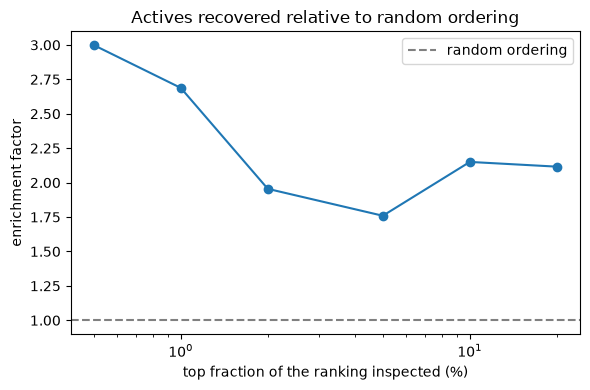

In [12]:
def plot_enrichment(enrichment_table):
    "Enrichment factor against the fraction of the ranking inspected."
    figure, axis = plt.subplots(figsize=(6, 4))
    axis.plot(100 * enrichment_table["fraction"], enrichment_table["enrichment"], marker="o")
    axis.axhline(1.0, color="gray", linestyle="--", label="random ordering")
    axis.set_xscale("log")
    axis.set_xlabel("top fraction of the ranking inspected (%)")
    axis.set_ylabel("enrichment factor")
    axis.set_title("Actives recovered relative to random ordering")
    axis.legend()
    figure.tight_layout()
    return axis


plot_enrichment(enrichment_table);

### Counts or presence only

The multinomial model uses how many times each fragment occurs. Binarizing the
features and fitting `BernoulliNB` instead keeps only whether a fragment is
present, and also models absences explicitly. The comparison shows what the
counts are worth on this dataset.

In [13]:
def fit_presence_classifier(features, labels, active_prior=None, smoothing=COUNT_SMOOTHING):
    "Bernoulli naive Bayes on fragment presence/absence, for comparison with the count model."
    class_prior = None if active_prior is None else [1.0 - active_prior, active_prior]
    model = BernoulliNB(alpha=smoothing, binarize=0.5, class_prior=class_prior)
    return model.fit(features, labels)


presence_model = fit_presence_classifier(train_features, train_labels, active_prior=ACTIVE_PRIOR)
_, presence_summary, presence_enrichment = evaluate_ranking(presence_model, test_features, test_labels)

comparison = pd.DataFrame([
    {"features": "counts (multinomial)", "roc_auc": summary["roc_auc"],
     "enrichment_top_1pct": enrichment_table.set_index("fraction").loc[0.01, "enrichment"]},
    {"features": "presence (bernoulli)", "roc_auc": presence_summary["roc_auc"],
     "enrichment_top_1pct": presence_enrichment.set_index("fraction").loc[0.01, "enrichment"]},
])
print(comparison.to_string(index=False, float_format="%.3f"))

            features  roc_auc  enrichment_top_1pct
counts (multinomial)    0.723                2.688
presence (bernoulli)    0.726                0.977


### Scoring new molecules

The model takes SMILES, applies the same featurization and returns the
probability of activity, which orders the library. Unparsable structures are
reported rather than silently dropped.

In [14]:
def score_molecules(model, smiles_list):
    "Probability of activity for new molecules, sorted from most to least promising."
    parsed, failed = [], []
    for smiles in smiles_list:
        molecule = Chem.MolFromSmiles(smiles)
        (parsed if molecule is not None else failed).append((smiles, molecule))
    if failed:
        print(f"{len(failed)} SMILES could not be parsed and were skipped, e.g. {failed[0][0]!r}")
    if not parsed:
        raise ValueError("None of the supplied SMILES could be parsed.")

    counts, _ = fragment_count_matrix([molecule for _, molecule in parsed])
    frame = pd.DataFrame({
        "smiles": [smiles for smiles, _ in parsed],
        "probability_active": model.predict_proba(counts)[:, 1],
    })
    return frame.sort_values("probability_active", ascending=False).reset_index(drop=True)


test_frame = dataset.iloc[test_index].reset_index(drop=True)
ranking = score_molecules(model, test_frame[SMILES_COLUMN].tolist())
ranking = ranking.merge(
    test_frame[[SMILES_COLUMN, LABEL_COLUMN]].rename(columns={SMILES_COLUMN: "smiles"}),
    on="smiles", how="left",
)
ranking.to_csv("naive_bayes_predictions.csv", index=False)
print(ranking.head(10).to_string(index=False, float_format="%.4f"))
print(f"\nsaved {len(ranking)} scored molecules to naive_bayes_predictions.csv")

                                                                                                                     smiles  probability_active activity
                                                               CCCCCCCCCCCCN1[C@H](C2=C(S1(=O)=O)C=CC(=C2)C(F)(F)F)CC(=O)OC              0.6789 inactive
                                                                                    CCCCCCCCCN1C2=C(CCCC2)C(=N)C3=C1CCC3.Br              0.6693   active
                                                                           CC1=CC(=CC(=C1C2=C(C(=NO2)C(F)(F)F)C3=CSC=N3)O)O              0.5867 inactive
                                                                                         CCCCCCCC1=CN=C(C=C1)C2=CC=C(C=C2)O              0.5849 inactive
                                                                              CCCCCCCCSC1=NN=C(O1)CSC2=NN3C(=CC(=NC3=N2)C)C              0.5638   active
CC1C(C(C(C(C(C(/C=C(/C2=C3C4=C(C(=C(C(=C4C(=O)C(=C3OCO2)C)O)NC(=O)/C(=C/C=C\C(C1O)

## Results, limitations and references

On the worked example (22,484 molecules, 2,044 active; 4,497 held out for
testing) the count model reached a cross-validated ROC-AUC of 0.718 on the
training set and 0.723 on the test set. Its value is visible in the ranking
rather than in the labels: the top 0.5% of the ranking contains 8 of the 22
compounds inspected (a 36% hit rate, 4.0 times the base rate), the top 1% 13 of
45 (29%, 3.2 times), and the advantage decays to about 2 times by the top 20%.
The MCC of 0.052 reflects the other side of the same result: with a prior of
0.97%, almost no compound reaches a posterior probability of 0.5, so the
active/inactive label the model would assign is close to useless while the order
it produces is not.

Keeping the counts matters for the top of the ranking but not for the overall
ordering: binarized features give a marginally higher ROC-AUC (0.728 against
0.723) and a much worse enrichment in the top 1% (1.2 against 3.2). An aggregate
measure over the whole ranking and the early-recognition behaviour that screening
depends on are not the same thing.

The fitted likelihood ratios are chemically legible. Nitro groups, thiazoles,
imidazoles, phenols and guanidines are the fragments most associated with
activity, consistent with the nitroaromatic and azole chemotypes known in
antitubercular compounds, while carboxylic acids, sulfonamides, hydrazines,
hydrazones and thiocarbonyl groups are associated with inactivity. These are
associations in one screen, not causal claims about mechanism.

Limitations:

- The hard label is not a usable output at this prior; only the ranking is. Any
  threshold applied to the probabilities has to be chosen for the number of
  compounds one intends to test, not at 0.5.
- The independence assumption does not hold: fragment counts are strongly
  correlated, since `fr_phenol` and `fr_Ar_OH`, or `fr_benzene` and
  `fr_bicyclic`, count overlapping features of the same molecule. Repeated
  evidence is therefore counted more than once and the probabilities are
  overconfident. The ranking tolerates this better than the calibration does.
- The 85 fragment counters describe common functional groups only. Five of them
  never occur in this dataset, and a molecule whose chemistry none of them
  recognizes would be scored on the prior alone.
- The file keeps a fixed 1:10 sample of the inactives, so the hit rates and
  enrichment factors above describe that subset, in which 9% of compounds are
  active, and not the full 211,608-compound screen. Enrichment measured on a
  subsample is not directly transferable to a library with a different base
  rate; reproducing these numbers on the whole screen requires downloading it.
- The labels come from a single-concentration threshold, not from potency, so
  "active" here says nothing about how active. The depositor also lists assay
  artifacts that can produce both false positives and false negatives, such as
  compounds that autofluoresce, absorb in the readout range or precipitate.
- The screen measures inhibition of bacterial growth in a cell-based assay, not
  binding to a defined target. Fragment associations therefore mix target
  engagement with permeability through the mycobacterial envelope and efflux,
  which is also why the method needs no protein structure.
- Scores rank compounds for experimental follow-up; they are not predictions of
  activity that can stand without assay confirmation.

References:

1. Oliveira, T.A.; Silva, M.P.; Maia, E.H.B.; Silva, A.M.; Taranto, A.G. Virtual
   Screening Algorithms in Drug Discovery: A Review Focused on Machine and Deep
   Learning Methods. *Drugs Drug Candidates* **2023**, 2, 311-334.
   https://doi.org/10.3390/ddc2020017
2. Ekins, S.; Reynolds, R.C.; Franzblau, S.G.; Wan, B.; Freundlich, J.S.; Bunin,
   B.A. Enhancing Hit Identification in *Mycobacterium tuberculosis* Drug
   Discovery Using Validated Dual-Event Bayesian Models. *PLoS ONE* **2013**, 8,
   e63240. https://doi.org/10.1371/journal.pone.0063240
3. Discovery of VEGFR2 inhibitors by integrating naive Bayesian classification,
   molecular docking and drug screening approaches. *RSC Advances* **2018**.
   https://doi.org/10.1039/C7RA12259D
4. PubChem BioAssay AID 1626: High Throughput Screen to Identify Inhibitors of
   *Mycobacterium tuberculosis* H37Rv (Southern Research Institute).
   https://pubchem.ncbi.nlm.nih.gov/bioassay/1626
5. Ananthan, S. et al. High-throughput screening for inhibitors of
   *Mycobacterium tuberculosis* H37Rv. *Tuberculosis* **2009**.
   https://pubmed.ncbi.nlm.nih.gov/19783214/
6. Truchon, J.-F.; Bayly, C.I. Evaluating virtual screening methods: good and bad
   metrics for the "early recognition" problem. *J. Chem. Inf. Model.* **2007**,
   47, 488-508. https://doi.org/10.1021/ci600426e
7. Pedregosa, F. et al. Scikit-learn: Machine Learning in Python. *J. Mach.
   Learn. Res.* **2011**, 12, 2825-2830.
8. RDKit: Open-source cheminformatics. https://www.rdkit.org